<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DBSCAN_Manhattan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 📐 1. Formulasi Matematis Manhattan Distance & Prinsip DBSCAN

### 1.1. Manhattan Distance
Jarak yang digunakan untuk menentukan tetangga:
$$d(x,y)=\sum_{i=1}^{p}|x_i-y_i|.$$

### 1.2. Lingkungan Kepadatan
DBSCAN membentuk lingkungan radius $\varepsilon$:
$$N_\varepsilon(x)=\{y:d(x,y)\leq\varepsilon\}.$$
Titik menjadi **core point** ketika $|N_\varepsilon(x)|\geq\mathrm{min\_samples}$,
dengan titik itu sendiri ikut dihitung. **Border point** berada dalam
jangkauan core point, tetapi tidak memenuhi jumlah minimum tetangga.
Label `-1` menunjukkan **noise**.

Semua baris dan fitur hasil StandardScaler digunakan untuk clustering.
Silhouette memakai seluruh data non-noise dan metrik jarak yang sama,
ketika jumlah klaster memenuhi syarat. PCA diterapkan untuk visualisasi.

In [ ]:
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# =======================================================================
# 1. SETUP & IMPORT LIBRARY
# =======================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

from sklearn.metrics import pairwise_distances

from sklearn.neighbors import NearestNeighbors
from sklearn import config_context

from itertools import combinations

from IPython.display import HTML, display as _display
# Tabel lebar tetap dapat dibaca dengan geser horizontal.
def display(*objects):
    for obj in objects:
        if isinstance(obj, pd.DataFrame):
            _display(HTML('<div style="overflow-x:auto">'+obj.to_html(index=False)+'</div>'))
        else:
            _display(obj)


In [ ]:
# =======================================================================
# 2. DATASET & PREPROCESSING
# =======================================================================
FILE = 'dataset_B_05_2020 (1).csv'
df = pd.read_csv(FILE)

print('Shape dataset:', df.shape)
print('Jumlah data:', df.shape[0])
print('Jumlah kolom:', df.shape[1])
display(df.head(3))

# Metadata dan label asli disimpan terpisah dari fitur clustering.
urls = df['url'].copy()
y_true = df['status'].copy()
labels = y_true.copy()
X = df.drop(columns=['url', 'status']).select_dtypes(include=np.number)
print('Shape fitur numerik:', X.shape)

# Imputasi median, penghapusan fitur konstan, lalu StandardScaler.
print('Missing value sebelum imputasi:', int(X.isna().sum().sum()))
X = X.fillna(X.median())
print('Missing value setelah imputasi:', int(X.isna().sum().sum()))

selector = VarianceThreshold(threshold=0)
X_sel = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()]
removed_features = X.columns[~selector.get_support()]
X_selected = pd.DataFrame(X_sel, columns=selected_features, index=X.index)
print('Fitur konstan yang dihapus:', list(removed_features))
print('Shape setelah seleksi fitur:', X_selected.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
df_after = pd.DataFrame(X_scaled, columns=selected_features, index=X.index)
print('Shape setelah StandardScaler:', X_scaled.shape)
display(df_after.head(3))


Shape dataset: (11430, 89)
Jumlah data: 11430
Jumlah kolom: 89


url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,ratio_nullHyperlinks,nb_extCSS,ratio_intRedirection,ratio_extRedirection,ratio_intErrors,ratio_extErrors,login_form,external_favicon,links_in_tags,submit_email,ratio_intMedia,ratio_extMedia,sfh,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,0,0,0,0,3,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,3,0,0,0,0,0,0,4,4,3,3,3,11,11,6,5.75,7.0,4.500000,0,0,0,0,0,0,17,0.529412,0.470588,0,0,0,0.875,0,0.5,0,0,80.0,0,100.0,0.0,0,0,0,0.0,0,0,0,0,1,0,45,-1,0,1,1,4,legitimate
http://shadetreetechnology.com/V4/validation/a111aedc8ae390eabcfa130e041a10a4,77,23,1,1,0,0,0,0,0,0,0,0,0,5,0,1,0,0,0,0,0,0,0,0,1,0.220779,0.0,0,0,0,0,0,1,0,0,0,0,1,0,4,4,2,19,2,32,19,32,15.75,19.0,14.666667,0,0,0,0,0,0,30,0.966667,0.033333,0,0,0,0.000,0,0.0,0,0,100.0,0,80.0,20.0,0,0,0,100.0,0,0,0,1,0,0,77,5767,0,0,1,2,phishing
https://support-appleld.com.secureupdate.duilawyeryork.com/ap/89e6a3b4b063b8d/?cmd=_update&dispatch=89e6a3b4b063b8d1b&locale=_,126,50,1,4,1,0,1,2,0,3,2,0,0,5,0,1,0,0,0,0,0,1,0,0,0,0.150794,0.0,0,0,0,1,0,3,1,0,0,0,1,0,12,2,2,3,2,17,13,17,8.25,8.4,8.142857,0,0,0,0,0,0,4,1.000000,0.000000,0,0,0,0.000,0,0.0,0,0,100.0,0,0.0,0.0,0,0,0,100.0,0,0,0,1,0,0,14,4004,5828815,0,1,0,phishing


Shape fitur numerik: (11430, 87)
Missing value sebelum imputasi: 0
Missing value setelah imputasi: 0
Fitur konstan yang dihapus: ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
Shape setelah seleksi fitur: (11430, 81)
Shape setelah StandardScaler: (11430, 81)


length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,nb_extCSS,ratio_extRedirection,ratio_extErrors,login_form,external_favicon,links_in_tags,ratio_intMedia,ratio_extMedia,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
-0.436327,-0.193964,-0.421020,0.379116,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,-0.081815,-0.083946,-0.685161,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,1.098907,-0.337729,-0.081271,-0.098673,0.798018,-0.594651,-0.267868,-0.01871,-0.04866,-0.264999,-0.229732,-0.148617,1.206090,-0.503825,-0.301425,-0.375276,-0.013229,-0.720143,-0.05621,-0.400711,0.224909,-0.057562,-0.512450,0.200505,-0.198974,0.107876,-0.197666,-0.363968,-0.189497,-0.082894,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.420926,-0.194034,0.605943,-0.284507,2.687711,2.801064,-0.260624,-0.890315,0.674877,1.235290,-0.605350,-0.03625,-0.077932,-0.948614,-0.033744,-0.03744,-0.377549,-1.860473,1.129194,-0.28037,-0.549299,-1.307594,-0.429340,6.978227,0.934264,0.320974
0.287067,0.177207,2.375182,-1.081136,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,-0.081815,-0.083946,0.377443,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,-0.893559,-0.337729,-0.081271,-0.098673,0.798018,1.876053,-0.267868,-0.01871,-0.04866,-0.264999,-0.229732,-0.148617,-1.933425,-0.503825,-0.301425,-0.375276,-0.013229,0.725201,-0.05621,-0.400711,0.224909,-0.509749,3.547014,-0.133086,0.751998,1.730002,0.929003,2.048202,3.164071,1.339666,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.342965,0.967464,-0.760717,-0.284507,-0.596511,-0.399922,-0.260624,-0.890315,1.156557,0.802838,-0.084312,-0.03625,-0.077932,1.610785,-0.033744,-0.03744,-0.377549,0.537498,-0.885587,-0.28037,-0.510022,0.548471,-0.429340,-0.143303,0.934264,-0.467407
1.173224,2.682613,2.375182,1.109242,0.001174,-0.142915,2.356473,2.237556,2.711505,1.534217,-0.081815,-0.083946,0.377443,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,-0.893559,2.300854,-0.081271,-0.098673,-1.253105,1.092856,-0.267868,-0.01871,-0.04866,-0.264999,4.352889,-0.148617,1.206090,1.984817,-0.301425,-0.375276,-0.013229,0.725201,-0.05621,1.035010,-0.194490,-0.509749,-0.512450,-0.133086,0.072732,0.513407,0.279002,0.239075,0.201752,0.426829,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.498886,1.056008,-0.864902,-0.284507,-0.596511,-0.399922,-0.260624,-0.890315,1.156557,-0.926971,-0.605350,-0.03625,-0.077932,1.610785,-0.033744,-0.03744,-0.377549,0.537498,-0.885587,-0.28037,-0.587348,-0.018839,2.491612,-0.143303,0.934264,-1.255788


### Contoh jarak Manhattan dengan library

P0, P1, dan P2 memakai seluruh fitur input model. Jarak dihitung dengan
`pairwise_distances(metric="manhattan")`. Buka **Rincian fitur** untuk melihat P0–P1.

Jarak per fitur dihitung dengan `paired_manhattan_distances`. Jumlah kontribusi fitur sama dengan jarak Manhattan keseluruhan.


In [ ]:
from IPython.display import HTML
from sklearn.metrics.pairwise import paired_manhattan_distances

EXAMPLE_NODES = [0, 1, 2]
DISTANCE_METRIC = 'manhattan'
EXAMPLE_METRIC = DISTANCE_METRIC
EXAMPLE_DATA = X_scaled

def tampilkan_fitur(x, y, nama_x, nama_y):
    feature_df = pd.DataFrame({'Fitur': selected_features, nama_x: x, nama_y: y})
    per_feature = paired_manhattan_distances(x[:, None], y[:, None])
    feature_df['Kontribusi jarak (builtin)'] = per_feature
    print(f'Jumlah kontribusi fitur: {per_feature.sum():.8f}')

    distance = pairwise_distances(x[None, :], y[None, :], metric=EXAMPLE_METRIC)[0, 0]
    np.testing.assert_allclose(feature_df['Kontribusi jarak (builtin)'].sum(), distance, atol=1e-10)
    print(f'{nama_x} -> {nama_y}: jarak {EXAMPLE_METRIC} builtin = {distance:.8f}')
    table = feature_df.to_html(index=False, float_format=lambda value: f'{value:.8f}')
    display(HTML(f'<details><summary>Rincian {len(feature_df)} fitur: {nama_x} ke {nama_y}</summary>'
                 f'<div style="overflow-x:auto">{table}</div></details>'))
    return feature_df

pair_rows = []
for a, b in combinations(EXAMPLE_NODES, 2):
    distance = pairwise_distances(EXAMPLE_DATA[a:a + 1], EXAMPLE_DATA[b:b + 1], metric=EXAMPLE_METRIC)[0, 0]
    pair_rows.append({'Pasangan': f'P{a} - P{b}', 'Jarak builtin': distance})
pair_distance_df = pd.DataFrame(pair_rows)
display(pair_distance_df.round(8))
a, b = EXAMPLE_NODES[:2]
feature_pair_df = tampilkan_fitur(EXAMPLE_DATA[a], EXAMPLE_DATA[b], f'P{a}', f'P{b}')


Pasangan,Jarak builtin
P0 - P1,58.498862
P0 - P2,73.599151
P1 - P2,52.856607


Jumlah kontribusi fitur: 58.49886247
P0 -> P1: jarak manhattan builtin = 58.49886247


Fitur,P0,P1,Kontribusi jarak (builtin)
length_url,-0.43632748,0.28706655,0.72339403
length_hostname,-0.19396372,0.17720743,0.37117115
ip,-0.42102044,2.37518157,2.79620202
nb_dots,0.37911625,-1.08113606,1.46025231
nb_hyphens,-0.47798396,-0.47798396,0.00000000
nb_at,-0.14291457,-0.14291457,0.00000000
nb_qm,-0.38746409,-0.38746409,0.00000000
nb_and,-0.19760370,-0.19760370,0.00000000
nb_eq,-0.29368288,-0.29368288,0.00000000
nb_underscore,-0.29512783,-0.29512783,0.00000000


## 2. Penentuan parameter DBSCAN

`MIN_SAMPLES` ditetapkan sebagai masukan. `EPS` dihitung dari siku K-distance pada metrik notebook ini, lalu digunakan oleh fit final, evaluasi, pemeriksaan tetangga, dan grafik. Kandidat siku adalah heuristik, bukan jaminan optimum universal.


In [ ]:
MIN_SAMPLES = 5
DBSCAN_OPTIONS = dict(algorithm='brute', n_jobs=1)
print('Metrik:', DISTANCE_METRIC)
print('MIN_SAMPLES:', MIN_SAMPLES)


Metrik: manhattan
MIN_SAMPLES: 5


### K-distance untuk menentukan EPS

Hitungan `MIN_SAMPLES` mencakup titik sendiri. Library menghitung jarak tetangga terdekat pada seluruh `X_scaled`, lalu mengurutkan jarak terakhir setiap baris. Siku dipilih melalui selisih terbesar antara garis diagonal dan kurva yang dinormalisasi. Nilai jarak pada siku menjadi `EPS` untuk model berikutnya.

Jika kurva tidak memiliki siku yang valid, proses berhenti agar parameter dapat diperiksa. Baca hasil klaster bersama persentase noise; siku bukan jaminan parameter terbaik.


EPS hasil K-distance yang dipakai untuk fit: 29.13636822013378


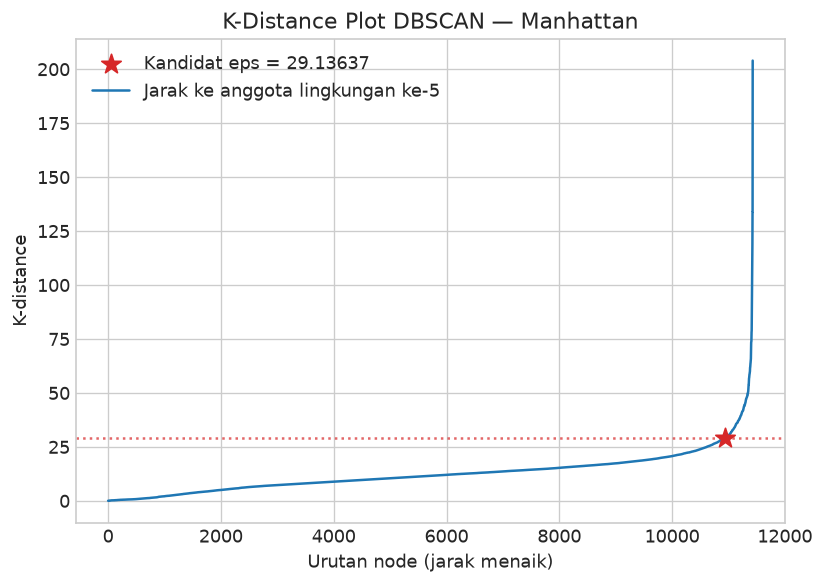

Metrik,MIN_SAMPLES (termasuk sendiri),k (selain sendiri),Kandidat eps (heuristik),EPS untuk fit
manhattan,5,4,29.136368,29.136368


Contoh urutan tetangga P0, P1, P2; jarak terakhir menjadi nilai K-distance node tersebut.
Pada jarak seri/duplikat, ID tetangga yang dipilih dapat berbeda; nilai jaraknya tetap sama.


Metrik,Node query,Urutan,Node tetangga,Jarak,Dalam EPS
manhattan,P0,1,P0,0.000000,True
manhattan,P0,2,P9333,19.582308,True
manhattan,P0,3,P4886,20.192799,True
manhattan,P0,4,P5912,21.543182,True
manhattan,P0,5,P2098,22.176390,True
manhattan,P1,1,P1,0.000000,True
manhattan,P1,2,P1651,0.146563,True
manhattan,P1,3,P766,0.210927,True
manhattan,P1,4,P3406,0.451820,True
manhattan,P1,5,P289,0.564735,True


In [ ]:
# Semua node digunakan; blok query membatasi memori matriks jarak sementara.
plot_metrics = [DISTANCE_METRIC]
k_distance_by_metric = {}
knee_eps_by_metric = {}
neighbor_examples = []
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(7 * len(plot_metrics), 5), squeeze=False)
for ax, metric in zip(axes.ravel(), plot_metrics):
    nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric=metric,
                          algorithm='brute', n_jobs=1).fit(X_scaled)
    # X diberikan secara eksplisit: hitungan mencakup jarak nol ke titik sendiri.
    with config_context(working_memory=128):
        distances, indices = nn.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])
    k_distance_by_metric[metric] = k_distances
    rank = np.arange(len(k_distances))
    candidate = np.nan
    if np.ptp(k_distances) > 0:
        x_norm = rank / (len(rank) - 1)
        y_norm = (k_distances - k_distances[0]) / np.ptp(k_distances)
        gap = x_norm - y_norm
        knee_index = int(np.argmax(gap))
        if 0 < knee_index < len(rank) - 1 and gap[knee_index] > 1e-6:
            candidate = float(k_distances[knee_index])
            ax.scatter(knee_index, candidate, color='tab:red', marker='*', s=150,
                       zorder=3, label=f'Kandidat eps = {candidate:.5f}')
            ax.axhline(candidate, color='tab:red', ls=':', alpha=0.7)
    knee_eps_by_metric[metric] = candidate
    ax.plot(rank, k_distances, label=f'Jarak ke anggota lingkungan ke-{MIN_SAMPLES}')
    ax.set(xlabel='Urutan node (jarak menaik)', ylabel='K-distance',
           title=f'K-Distance Plot DBSCAN — {metric.title()}')
    ax.legend()
    for node in EXAMPLE_NODES:
        for j in range(MIN_SAMPLES):
            neighbor_examples.append({'Metrik': metric, 'Node query': f'P{node}',
                'Urutan': j + 1, 'Node tetangga': f'P{indices[node, j]}',
                'Jarak': distances[node, j]})
    del nn, distances, indices
EPS = float(knee_eps_by_metric[DISTANCE_METRIC])
if not np.isfinite(EPS) or EPS <= 0:
    raise ValueError('Siku K-distance tidak valid; periksa kurva dan MIN_SAMPLES.')
neighbor_examples_df = pd.DataFrame(neighbor_examples)
neighbor_examples_df['Dalam EPS'] = neighbor_examples_df['Jarak'] <= EPS
print('EPS hasil K-distance yang dipakai untuk fit:', EPS)
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'Metrik': m, 'MIN_SAMPLES (termasuk sendiri)': MIN_SAMPLES,
    'k (selain sendiri)': MIN_SAMPLES - 1,
    'Kandidat eps (heuristik)': knee_eps_by_metric[m], 'EPS untuk fit': EPS}
    for m in plot_metrics]).round(6))
print('Contoh urutan tetangga P0, P1, P2; jarak terakhir menjadi nilai K-distance node tersebut.')
print('Pada jarak seri/duplikat, ID tetangga yang dipilih dapat berbeda; nilai jaraknya tetap sama.')
display(neighbor_examples_df.round(8))


In [ ]:
# =======================================================================
# 4. EKSEKUSI CLUSTERING DBSCAN
# =======================================================================
dbscan = DBSCAN(
    eps=EPS,
    min_samples=MIN_SAMPLES,
    metric=DISTANCE_METRIC,
    **DBSCAN_OPTIONS
)

cluster_labels = dbscan.fit_predict(X_scaled)

print("Jumlah label cluster:", len(cluster_labels))

assert dbscan.eps == knee_eps_by_metric[DISTANCE_METRIC]
np.testing.assert_array_equal(cluster_labels, dbscan.labels_)


Jumlah label cluster: 11430


In [ ]:
# =======================================================================
# 5. HASIL KLASTER, NOISE, & METRIK EVALUASI
# =======================================================================
noise_mask = cluster_labels == -1
core_mask = np.zeros(len(cluster_labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
border_mask = (~noise_mask) & (~core_mask)

n_clusters = len(set(cluster_labels)) - int(noise_mask.any())
n_noise = int(noise_mask.sum())

print("Metrik jarak:", DISTANCE_METRIC)
print("Jumlah cluster (tanpa noise):", n_clusters)
print("Jumlah core point:", int(core_mask.sum()))
print("Jumlah border point:", int(border_mask.sum()))
print("Jumlah noise:", n_noise)
print(f"Persentase noise: {100 * noise_mask.mean():.2f}%")

cluster_counts = (
    pd.Series(cluster_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Jumlah Data")
)

cluster_counts["Persentase (%)"] = (
    cluster_counts["Jumlah Data"] / len(cluster_labels) * 100
).round(2)

display(cluster_counts)

X_evaluation = X_scaled[~noise_mask]
labels_evaluation = cluster_labels[~noise_mask]
n_evaluation_clusters = len(np.unique(labels_evaluation))

silhouette = None

if 2 <= n_evaluation_clusters < len(labels_evaluation):
    silhouette = silhouette_score(
        X_evaluation,
        labels_evaluation,
        metric=DISTANCE_METRIC
    )
    print("Jumlah data evaluasi (seluruh data non-noise):", len(labels_evaluation))
    print("Jumlah cluster pada data evaluasi:", n_evaluation_clusters)
    print(f"Silhouette score ({DISTANCE_METRIC}): {silhouette:.4f}")
else:
    print("Silhouette tidak dihitung: data evaluasi tidak memenuhi syarat jumlah cluster.")

eval_df = pd.DataFrame([{
    'Distance Metric': DISTANCE_METRIC.title(),
    'EPS': dbscan.eps,
    'MIN_SAMPLES': dbscan.min_samples,
    'Jumlah Klaster': n_clusters,
    'Core Point': int(core_mask.sum()),
    'Border Point': int(border_mask.sum()),
    'Noise': n_noise,
    'Noise (%)': 100 * noise_mask.mean(),
    'Silhouette Score': silhouette if silhouette is not None else np.nan,
}])
display(eval_df.round(4))


Metrik jarak: manhattan
Jumlah cluster (tanpa noise): 16
Jumlah core point: 10940
Jumlah border point: 137
Jumlah noise: 353
Persentase noise: 3.09%


Cluster,Jumlah Data,Persentase (%)
-1,353,3.09
0,10868,95.08
1,20,0.17
2,6,0.05
3,6,0.05
4,74,0.65
5,5,0.04
6,6,0.05
7,15,0.13
8,5,0.04


Jumlah data evaluasi (seluruh data non-noise): 11077
Jumlah cluster pada data evaluasi: 16
Silhouette score (manhattan): 0.2557


Distance Metric,EPS,MIN_SAMPLES,Jumlah Klaster,Core Point,Border Point,Noise,Noise (%),Silhouette Score
Manhattan,29.1364,5,16,10940,137,353,3.0884,0.2557


### Lingkungan node contoh

Library menghitung jarak ke seluruh dataset. Tetangga memenuhi `jarak <= EPS`,
termasuk node itu sendiri. Core point memiliki sedikitnya `MIN_SAMPLES` tetangga.


In [ ]:
example_distances = pairwise_distances(X_scaled[EXAMPLE_NODES], X_scaled, metric=DISTANCE_METRIC)
node_rows = []
for row, node in enumerate(EXAMPLE_NODES):
    example_distances[row, node] = 0.0
    count = int((example_distances[row] <= dbscan.eps).sum())
    np.testing.assert_equal(count >= dbscan.min_samples, bool(core_mask[node]))
    kind = 'core' if core_mask[node] else ('noise' if cluster_labels[node] == -1 else 'border')
    node_rows.append({'Node': f'P{node}', 'Tetangga dalam EPS (termasuk sendiri)': count,
        'MIN_SAMPLES': dbscan.min_samples, 'Tipe': kind, 'Label hasil fit': int(cluster_labels[node])})
node_summary_df = pd.DataFrame(node_rows)
display(node_summary_df)


Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Tipe,Label hasil fit
P0,202,5,core,0
P1,186,5,core,0
P2,353,5,core,0


Total explained variance PCA: 15.51%


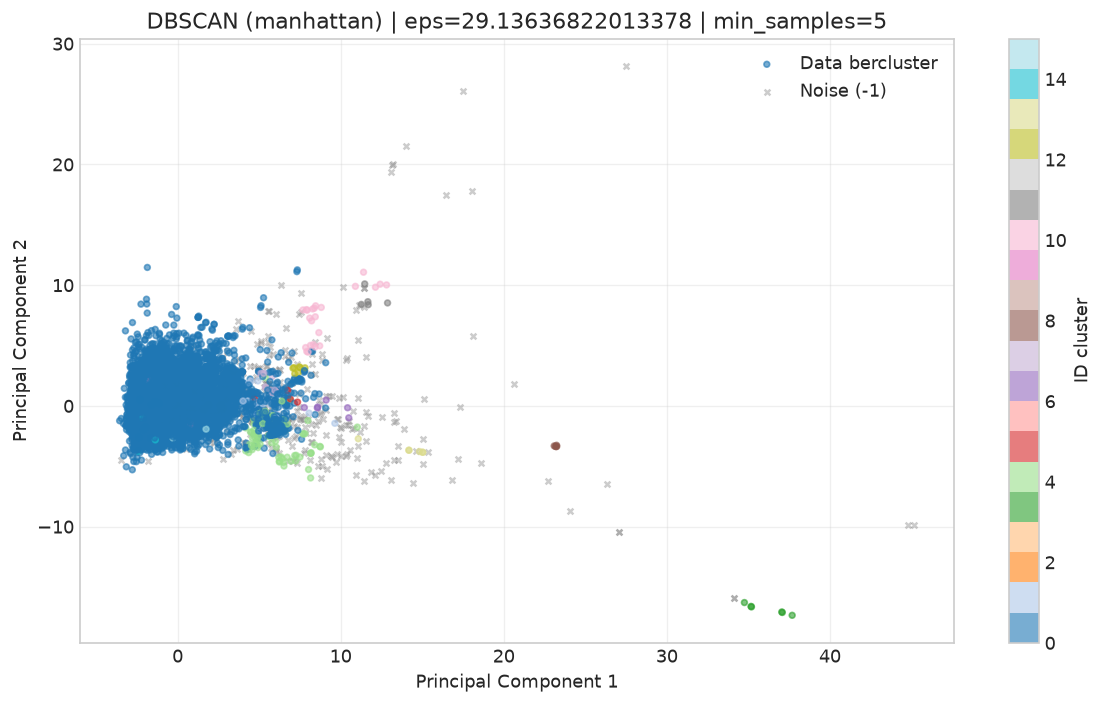

In [ ]:
# =======================================================================
# 6. VISUALISASI PCA 2D PEMETAAN KLASTER & NOISE
# =======================================================================
pca = PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(f"Total explained variance PCA: {pca.explained_variance_ratio_.sum():.2%}")

fig, ax = plt.subplots(figsize=(10, 6))

if (~noise_mask).any():
    points = ax.scatter(
        X_pca[~noise_mask, 0],
        X_pca[~noise_mask, 1],
        c=cluster_labels[~noise_mask],
        cmap="tab20",
        s=12,
        alpha=0.6,
        zorder=2,
        label="Data bercluster"
    )
    if n_clusters > 1:
        fig.colorbar(
            points,
            ax=ax,
            label="ID cluster",
            ticks=np.unique(cluster_labels[~noise_mask]) if n_clusters <= 10 else None
        )

if noise_mask.any():
    ax.scatter(
        X_pca[noise_mask, 0],
        X_pca[noise_mask, 1],
        c="gray",
        marker="x",
        s=12,
        alpha=0.4,
        zorder=1,
        label="Noise (-1)"
    )

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title(
    f"DBSCAN ({DISTANCE_METRIC}) | eps={dbscan.eps} | min_samples={dbscan.min_samples}"
)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()
